03_downstream_classification.ipynb

1. Setup
2. Load dataset
3. Load trained SimCLR model
4. Extract 512-D features + labels
5. Train/validation/test split
6. Train downstream classifier
7. Evaluate
8. Confusion matrix
9. PCA visualization
10. t-SNE visualization
11. Save classifier and results

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torchvision.models as models

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
dataset_path = "/content/drive/MyDrive/NEU-DET/train/images"

model_path = "/content/drive/MyDrive/METALYX/models/simclr_resnet18.pth"

output_dir = "/content/drive/MyDrive/METALYX/results"

os.makedirs(output_dir, exist_ok=True)

print("Dataset:", dataset_path)
print("Model:", model_path)
print("Results:", output_dir)

Dataset: /content/drive/MyDrive/NEU-DET/train/images
Model: /content/drive/MyDrive/METALYX/models/simclr_resnet18.pth
Results: /content/drive/MyDrive/METALYX/results


Check the feature file

In [ ]:
import numpy as np

features = np.load(
    "/content/drive/MyDrive/METALYX/models/simclr_features.npy"
)

print("Feature shape:", features.shape)
print("Data type:", features.dtype)
print("Contains NaN:", np.isnan(features).any())

Feature shape: (1440, 512)
Data type: float32
Contains NaN: False


Check files

In [ ]:
print("Dataset exists:", os.path.exists(dataset_path))
print("Model exists:", os.path.exists(model_path))

if not os.path.exists(dataset_path):
    raise FileNotFoundError("Dataset path not found.")

if not os.path.exists(model_path):
    raise FileNotFoundError("SimCLR model not found.")

Dataset exists: True
Model exists: True


Define the six classes

In [ ]:
class_names = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches"
]

class_to_idx = {
    class_name: idx
    for idx, class_name in enumerate(class_names)
}

idx_to_class = {
    idx: class_name
    for class_name, idx in class_to_idx.items()
}

print(class_to_idx)

{'crazing': 0, 'inclusion': 1, 'patches': 2, 'pitted_surface': 3, 'rolled-in_scale': 4, 'scratches': 5}


Load image paths and labels

In [ ]:
image_extensions = (".jpg", ".jpeg", ".png", ".bmp")

image_paths = []
labels = []

for class_name in class_names:

    class_dir = os.path.join(dataset_path, class_name)

    if not os.path.isdir(class_dir):
        print("Warning: folder not found:", class_dir)
        continue

    class_images = sorted([
        os.path.join(class_dir, file)
        for file in os.listdir(class_dir)
        if file.lower().endswith(image_extensions)
    ])

    image_paths.extend(class_images)
    labels.extend(
        [class_to_idx[class_name]] * len(class_images)
    )

print("Total images:", len(image_paths))
print("Total labels:", len(labels))

Total images: 1440
Total labels: 1440


Check class distribution

In [ ]:
label_counts = pd.Series(labels).value_counts().sort_index()

for idx, count in label_counts.items():
    print(f"{idx_to_class[idx]:20s}: {count}")

crazing             : 240
inclusion           : 240
patches             : 240
pitted_surface      : 240
rolled-in_scale     : 240
scratches           : 240


Create feature extraction transform

In [ ]:
feature_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

Define SimCLR model

In [ ]:
class SimCLR(nn.Module):

    def __init__(self, projection_dim=128):

        super(SimCLR, self).__init__()

        self.encoder = models.resnet18(weights=None)

        num_features = self.encoder.fc.in_features

        self.encoder.fc = nn.Identity()

        self.projector = nn.Sequential(
            nn.Linear(num_features, 512),
            nn.ReLU(),
            nn.Linear(512, projection_dim)
        )

    def forward(self, x):

        features = self.encoder(x)

        projections = self.projector(features)

        return features, projections

Load trained SimCLR model

In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

model = SimCLR(
    projection_dim=128
).to(device)

checkpoint = torch.load(
    model_path,
    map_location=device
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Trained SimCLR model loaded successfully.")

Using device: cuda
Trained SimCLR model loaded successfully.


Extract features and labels

In [ ]:
features = []
feature_labels = []

model.eval()

with torch.no_grad():

    for image_path, label in zip(image_paths, labels):

        image = cv2.imread(image_path)

        if image is None:
            print("Warning: could not read:", image_path)
            continue

        image = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )

        image_tensor = feature_transform(image)
        image_tensor = image_tensor.unsqueeze(0).to(device)

        feature, _ = model(image_tensor)

        features.append(
            feature.cpu().numpy().squeeze()
        )

        feature_labels.append(label)

features = np.asarray(features, dtype=np.float32)
feature_labels = np.asarray(feature_labels)

print("Feature shape:", features.shape)
print("Label shape:", feature_labels.shape)

Feature shape: (1440, 512)
Label shape: (1440,)


Verify features

In [ ]:
print("Data type:", features.dtype)
print("Contains NaN:", np.isnan(features).any())
print("Contains Inf:", np.isinf(features).any())

Data type: float32
Contains NaN: False
Contains Inf: False


Save features with labels

In [ ]:
feature_output_path = os.path.join(
    output_dir,
    "simclr_features_with_labels.npz"
)

np.savez(
    feature_output_path,
    features=features,
    labels=feature_labels,
    image_paths=np.array(image_paths)
)

print("Saved:")
print(feature_output_path)

Saved:
/content/drive/MyDrive/METALYX/results/simclr_features_with_labels.npz


512-D SimCLR features → train/test split → downstream classifier → evaluation

In [ ]:
# Load the saved features, labels, and image paths

data = np.load(
    "/content/drive/MyDrive/METALYX/results/simclr_features_with_labels.npz",
    allow_pickle=True
)

features = data["features"]
labels = data["labels"]
image_paths = data["image_paths"]

print("Features shape:", features.shape)
print("Labels shape:", labels.shape)
print("Image paths:", len(image_paths))

Features shape: (1440, 512)
Labels shape: (1440,)
Image paths: 1440


In [ ]:
# Check class distribution

for class_id, class_name in enumerate(class_names):
    count = np.sum(labels == class_id)
    print(f"{class_name:20s}: {count}")

downstream classification

In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(
    features,
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (1008, 512)
Validation: (216, 512)
Testing: (216, 512)


Train the classifier

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

classifier = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

classifier.fit(X_train, y_train)

print("Downstream classifier trained successfully.")

Downstream classifier trained successfully.


Validation accuracy

In [ ]:
from sklearn.metrics import accuracy_score

y_val_pred = classifier.predict(X_val)

val_accuracy = accuracy_score(y_val, y_val_pred)

print(f"Validation Accuracy: {val_accuracy:.4f}")
print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")

Validation Accuracy: 0.9630
Validation Accuracy: 96.30%


Final test accuracy

In [ ]:
y_test_pred = classifier.predict(X_test)

test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Accuracy: 0.9676
Test Accuracy: 96.76%


Classification report

In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=class_names,
        digits=4
    )
)

                 precision    recall  f1-score   support

        crazing     1.0000    1.0000    1.0000        36
      inclusion     0.9394    0.8611    0.8986        36
        patches     1.0000    1.0000    1.0000        36
 pitted_surface     0.8718    0.9444    0.9067        36
rolled-in_scale     1.0000    1.0000    1.0000        36
      scratches     1.0000    1.0000    1.0000        36

       accuracy                         0.9676       216
      macro avg     0.9685    0.9676    0.9675       216
   weighted avg     0.9685    0.9676    0.9675       216



# visualization

Calculate the overall metrics

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

precision = precision_score(
    y_test,
    y_test_pred,
    average="weighted"
)

recall = recall_score(
    y_test,
    y_test_pred,
    average="weighted"
)

f1 = f1_score(
    y_test,
    y_test_pred,
    average="weighted"
)

print(f"Accuracy : {test_accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall   : {recall * 100:.2f}%")
print(f"F1-score : {f1 * 100:.2f}%")

Accuracy : 96.76%
Precision: 96.85%
Recall   : 96.76%
F1-score : 96.75%


# Confusion matrix

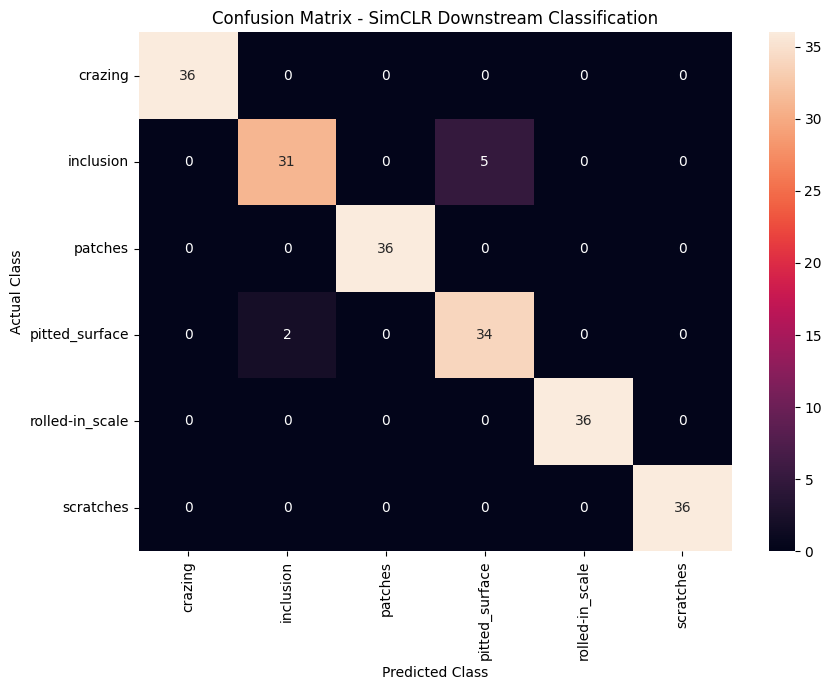

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_test,
    y_test_pred
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix - SimCLR Downstream Classification")

plt.tight_layout()

plt.show()

Save the confusion matrix

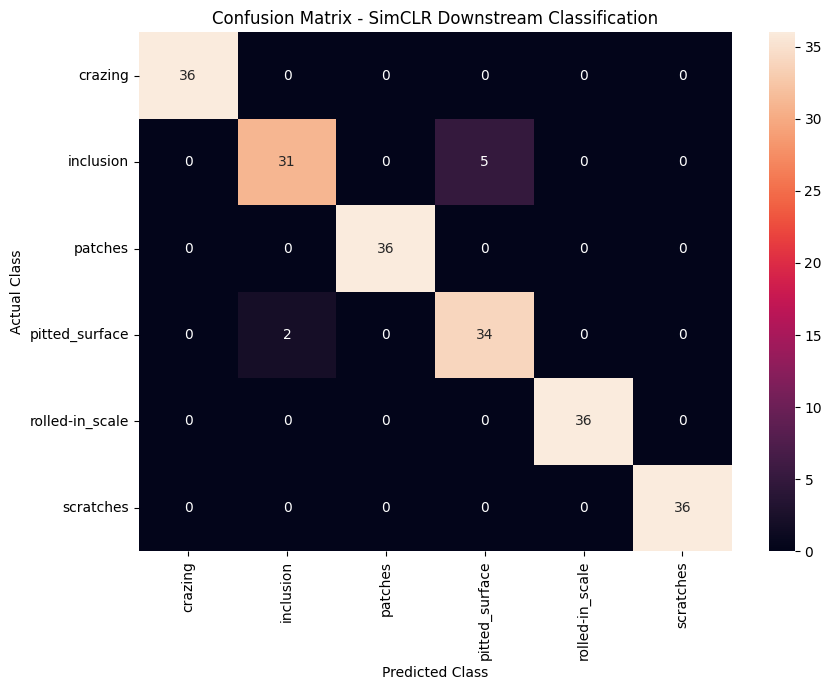

Saved: /content/drive/MyDrive/METALYX/results/confusion_matrix.png


In [ ]:
output_dir = "/content/drive/MyDrive/METALYX/results"

cm_path = os.path.join(
    output_dir,
    "confusion_matrix.png"
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix - SimCLR Downstream Classification")

plt.tight_layout()

plt.savefig(
    cm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", cm_path)

# PCA visualization

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(
    n_components=2,
    random_state=42
)

features_pca = pca.fit_transform(features)

print("Original feature shape:", features.shape)
print("PCA feature shape:", features_pca.shape)

print(
    "Explained variance ratio:",
    pca.explained_variance_ratio_
)

print(
    "Total explained variance:",
    pca.explained_variance_ratio_.sum()
)

Original feature shape: (1440, 512)
PCA feature shape: (1440, 2)
Explained variance ratio: [0.25363287 0.21578164]
Total explained variance: 0.46941453


Plot the PCA features

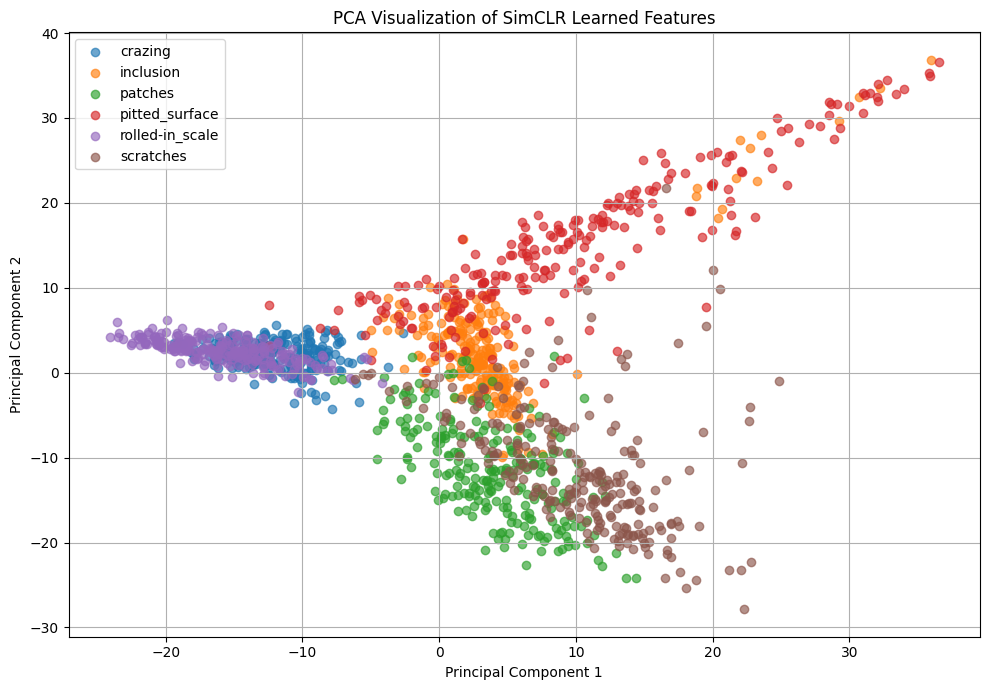

In [ ]:
plt.figure(figsize=(10, 7))

for class_id, class_name in enumerate(class_names):

    mask = labels == class_id

    plt.scatter(
        features_pca[mask, 0],
        features_pca[mask, 1],
        label=class_name,
        alpha=0.65
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title(
    "PCA Visualization of SimCLR Learned Features"
)

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

In [ ]:
pca_path = os.path.join(
    output_dir,
    "simclr_pca_visualization.png"
)

plt.savefig(
    pca_path,
    dpi=300,
    bbox_inches="tight"
)

print("Saved:", pca_path)

Saved: /content/drive/MyDrive/METALYX/results/simclr_pca_visualization.png


<Figure size 640x480 with 0 Axes>

# t-SNE

In [ ]:
from sklearn.manifold import TSNE

tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=42,
    init="pca",
    learning_rate="auto"
)

features_tsne = tsne.fit_transform(features)

print("t-SNE shape:", features_tsne.shape)

t-SNE shape: (1440, 2)


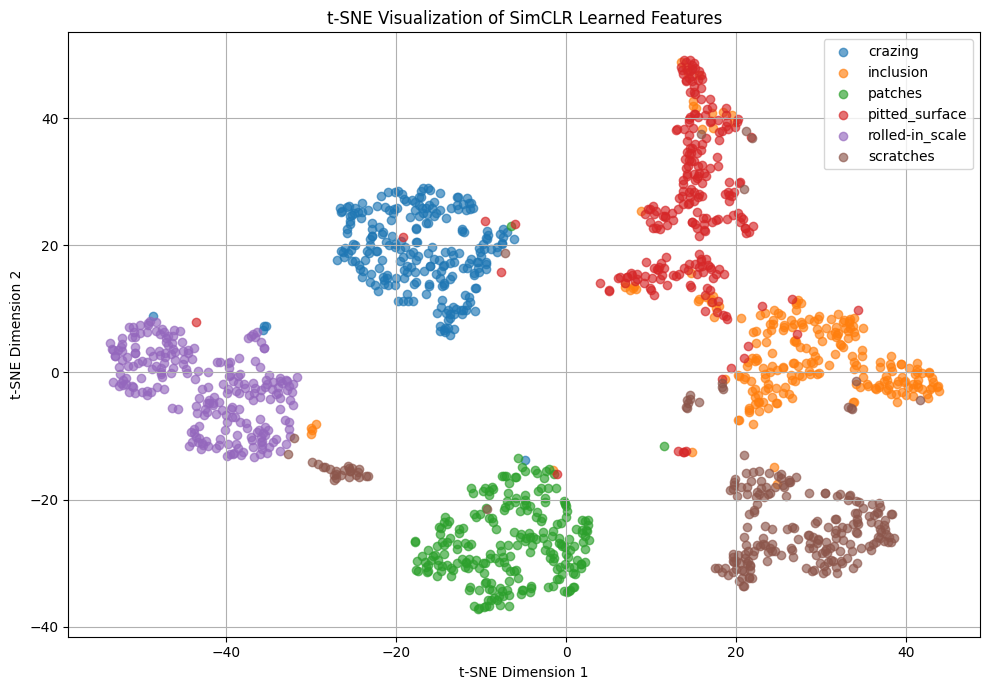

In [ ]:
plt.figure(figsize=(10, 7))

for class_id, class_name in enumerate(class_names):

    mask = labels == class_id

    plt.scatter(
        features_tsne[mask, 0],
        features_tsne[mask, 1],
        label=class_name,
        alpha=0.65
    )

plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")

plt.title(
    "t-SNE Visualization of SimCLR Learned Features"
)

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

In [ ]:
tsne_path = os.path.join(
    output_dir,
    "simclr_tsne_visualization.png"
)

plt.savefig(
    tsne_path,
    dpi=300,
    bbox_inches="tight"
)

print("Saved:", tsne_path)

Saved: /content/drive/MyDrive/METALYX/results/simclr_tsne_visualization.png


<Figure size 640x480 with 0 Axes>

Save the classifier

In [ ]:
import joblib
import os

classifier_path = os.path.join(
    output_dir,
    "simclr_downstream_classifier.pkl"
)

joblib.dump(
    classifier,
    classifier_path
)

print("Classifier saved to:")
print(classifier_path)

Classifier saved to:
/content/drive/MyDrive/METALYX/results/simclr_downstream_classifier.pkl


Save the final metrics

In [ ]:
results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score"
    ],
    "Score": [
        test_accuracy,
        precision,
        recall,
        f1
    ]
})

results["Percentage"] = results["Score"] * 100

results_path = os.path.join(
    output_dir,
    "downstream_classification_results.csv"
)

results.to_csv(
    results_path,
    index=False
)

display(results)

print("Results saved to:")
print(results_path)

,Metric,Score,Percentage
0,Accuracy,0.967593,96.759259
1,Precision,0.968531,96.853147
2,Recall,0.967593,96.759259
3,F1-score,0.967536,96.753623


Results saved to:
/content/drive/MyDrive/METALYX/results/downstream_classification_results.csv


Save the classification report

In [ ]:
report = classification_report(
    y_test,
    y_test_pred,
    target_names=class_names,
    output_dict=True
)

report_df = pd.DataFrame(report).transpose()

report_path = os.path.join(
    output_dir,
    "classification_report.csv"
)

report_df.to_csv(report_path)

print("Classification report saved to:")
print(report_path)

Classification report saved to:
/content/drive/MyDrive/METALYX/results/classification_report.csv
